# Task 3 — Honest baselines: Dummy, Logistic Regression, Decision Tree

**Goal:** train the simplest possible models, score them with stratified 5-fold cross-validation, and compare with the `baseline_benchmarks` sheet. A baseline tells us how hard the problem is; any fancier model later has to beat these *honestly*.

**Three rules used throughout**
1. The Task 2 feature pipeline sits **inside** every model, so imputers, scalers and encoders are re-fitted on the training part of each fold only (nothing from the held-out fold leaks into preprocessing).
2. **One list of folds** (fixed random state) is built once and reused by every model.
3. Scores come from **out-of-fold predictions**: each row is predicted by a model that never saw it. A cross-validated ROC-AUC above 0.9 stops the notebook (go and look for leakage).

| # | Section |
|---|---------|
| 1 | Define X and y |
| 2 | One set of stratified folds |
| 3 | Dummy classifier |
| 4 | Logistic regression: scores vs yes/no predictions |
| 5 | Decision tree: why training scores lie |
| 6 | Comparison with the benchmark sheet |
| 7 | Is the gap believable? (noise and controls) |
| 8 | Leakage alarm |
| 9 | The 5-sentence note |

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, roc_auc_score
from sklearn.base import clone

ROOT = Path.cwd().resolve()
while not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from cortexhr.paths import FIGURES, TABLES, REPORTS
from cortexhr.baselines import (RANDOM_STATE, N_SPLITS, SUSPICIOUS_AUC, SuspiciouslyGoodScoreError, load_model_table, make_folds,
                                make_models, model_pipeline, out_of_fold_proba, per_fold_scores, summarise, score_predictions,
                                bootstrap_auc_interval, resubstitution_auc, check_suspicious_scores, load_benchmarks)
from cortexhr.features import build_pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)
for d in (FIGURES, TABLES): d.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GREY, RED, GREEN = "#2F5D8A", "#E07B39", "#9AA5B1", "#C0392B", "#3B8C5A"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9.5, "axes.titleweight": "bold"})
R = {}      # numbers saved to reports/tables/day3_findings.json

## 1. Define X and y
`X` = the allowed input columns (Task 2: target, identifiers and leaks are refused by `select_features`). `y` = `left_within_12m`, kept as a separate Series.

*Note on "X = pipeline output":* the task suggests using the pipeline's output as X. If we transformed all rows first and cross-validated afterwards, the imputer medians and scaler statistics would already have seen the held-out rows. Instead `X` stays as raw inputs and the pipeline is the first step of every model, which gives the same features without that leak (section 7 measures whether it matters here).

In [2]:
X, y, source = load_model_table()
R["rows"], R["inputs"], R["leavers"] = len(X), X.shape[1], int(y.sum())
R["leaver_rate"] = float(y.mean())
print(f"X: {X.shape[0]:,} rows x {X.shape[1]} input columns | y: {int(y.sum())} leavers ({100*y.mean():.2f}%)")
print("target in X?", "left_within_12m" in X.columns)
print("rows by source:", source.value_counts().to_dict(), "| leavers by source:", y.groupby(source).sum().to_dict())
X.head(3).T.head(8)

X: 2,379 rows x 33 input columns | y: 349 leavers (14.67%)
target in X? False
rows by source: {'historical_extension': 2000, 'master_employee_snapshot': 379} | leavers by source: {'historical_extension': 299, 'master_employee_snapshot': 50}


,0,1,2
job_level,4,3,1
tenure_months,164,162,154
total_experience_years,30.8,17.5,12.8
previous_employers_count,1,1,0
commute_distance_km,12.2,NaN,44.5
annual_fixed_pay,1733520,1247256,288492
comp_ratio,0.989,0.854,0.872
raises_received,6,6,7


*(Row count is 2,379 rather than 2,389: Task 1 removed the 6 duplicate rows, and the 4 negative-tenure rows are left out until the Python team answers open item O1.)*

## 2. One set of stratified folds
Stratified = every fold keeps about the same share of leavers (~14.7%). The folds are created once with a fixed random state and the **same list** is handed to every model.

In [3]:
folds = make_folds(y)                                   # StratifiedKFold(5, shuffle=True, random_state=42)
fold_table = pd.DataFrame({"fold": range(1, N_SPLITS + 1),
                           "test_rows": [len(te) for _, te in folds],
                           "test_leavers": [int(y.iloc[te].sum()) for _, te in folds],
                           "leaver_share_%": [round(100 * y.iloc[te].mean(), 2) for _, te in folds]})
display(fold_table)
every_row_once = sorted(np.concatenate([te for _, te in folds])) == list(range(len(y)))
print("every row is in exactly one test fold:", every_row_once, "| random_state =", RANDOM_STATE)
R["fold_table"] = fold_table.to_dict("records")

,fold,test_rows,test_leavers,leaver_share_%
0,1,476,70,14.71
1,2,476,70,14.71
2,3,476,70,14.71
3,4,476,70,14.71
4,5,475,69,14.53


every row is in exactly one test fold: True | random_state = 42


## 3. Dummy classifier: always guess the majority
It predicts "stays" for everyone. It learns nothing, so it shows the score we get for free.

In [4]:
models = make_models()
oof, summary = {}, {}
def run(name, estimator=None, X_=X, y_=y, folds_=folds, **kw):
    est = estimator if estimator is not None else model_pipeline(models[name], **kw)
    p = out_of_fold_proba(est, X_, y_, folds_)
    oof[name] = p; summary[name] = summarise(y_, p, folds_)
    return p

run("Dummy (always stays)")
s = summary["Dummy (always stays)"]
print(f"Dummy: accuracy {s['accuracy_mean']:.3f} | ROC-AUC {s['roc_auc_mean']:.3f} | PR-AUC {s['pr_auc_mean']:.3f} | recall {s['recall_mean']:.3f}")
print(f"(share of stayers = {1 - y.mean():.3f}; share of leavers = {y.mean():.3f})")

Dummy: accuracy 0.853 | ROC-AUC 0.500 | PR-AUC 0.147 | recall 0.000
(share of stayers = 0.853; share of leavers = 0.147)


**Reading the Dummy result.** Accuracy is high (~85%) simply because ~85% of people stay; the model catches **no one** (recall 0). Its ROC-AUC is exactly 0.5 because every row gets the same score, so it cannot rank anybody above anybody else. Its PR-AUC equals the share of leavers (~0.147), which is the floor for that metric. Anything we build has to beat 0.5 ROC-AUC and 0.147 PR-AUC, and has to do it without leaning on accuracy.

## 4. Logistic regression (`class_weight="balanced"`)
`balanced` makes each leaver count about six times as much as a stayer during training, so the model is not rewarded for ignoring the rare class.

In [5]:
run("Logistic Regression (balanced)")
s = summary["Logistic Regression (balanced)"]
print(f"ROC-AUC {s['roc_auc_mean']:.3f} +/- {s['roc_auc_sd']:.3f} (mean +/- sd over 5 folds) | pooled {s['roc_auc_pooled']:.3f} | PR-AUC {s['pr_auc_mean']:.3f}")
display(per_fold_scores(y, oof["Logistic Regression (balanced)"], folds).round(3))

ROC-AUC 0.712 +/- 0.018 (mean +/- sd over 5 folds) | pooled 0.710 | PR-AUC 0.309


,roc_auc,pr_auc,precision,recall,f1,accuracy
fold,,,,,,
0,0.683,0.318,0.244,0.586,0.345,0.672
1,0.734,0.335,0.282,0.629,0.389,0.710
2,0.719,0.318,0.303,0.671,0.418,0.725
3,0.710,0.276,0.250,0.600,0.353,0.676
4,0.714,0.297,0.245,0.681,0.360,0.648


### Scores vs yes/no predictions
The model outputs a **score** (probability of leaving) for every row. ROC-AUC and PR-AUC judge the *ranking* of those scores. A yes/no answer needs a **threshold**; here the default 0.5.

In [6]:
p = oof["Logistic Regression (balanced)"]
yes = (p >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y, yes).ravel()
print(f"At threshold 0.5: flagged {yes.sum()} of {len(y)} people as 'will leave' ({100*yes.mean():.1f}%)")
print(f"  caught {tp} of {tp+fn} leavers (recall {tp/(tp+fn):.2f}); {fp} stayers wrongly flagged; only {100*tp/(tp+fp):.1f}% of flags are right (precision)")
print("score distribution  leavers: median %.2f | stayers: median %.2f" % (np.median(p[y == 1]), np.median(p[y == 0])))
R["lr_confusion_at_0.5"] = {"tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn), "flagged_share": float(yes.mean())}

At threshold 0.5: flagged 839 of 2379 people as 'will leave' (35.3%)
  caught 221 of 349 leavers (recall 0.63); 618 stayers wrongly flagged; only 26.3% of flags are right (precision)
score distribution  leavers: median 0.59 | stayers: median 0.35


Same scores, very different stories: the **ranking** is modestly useful (ROC-AUC ~0.71) but at 0.5 the model flags about a third of the company to catch most leavers, and most of those flags are wrong. Choosing the threshold (and the metrics that go with it) is Task 4.

## 5. Decision tree: why training scores lie
*Think for yourself:* a tree with no depth limit can keep splitting until every training row sits alone in a leaf. We train two trees and compare the score on the rows the model was **fitted on** (resubstitution, not an honest score) with the cross-validated score.

In [7]:
run("Decision Tree (no depth limit, balanced)")
run("Decision Tree (depth 4, balanced)")
rows = []
for name in ["Logistic Regression (balanced)", "Decision Tree (depth 4, balanced)", "Decision Tree (no depth limit, balanced)"]:
    train_auc = resubstitution_auc(model_pipeline(clone(models[name])), X, y)
    rows.append({"model": name, "AUC on its own training rows": round(train_auc, 3),
                 "AUC in cross-validation": round(summary[name]["roc_auc_pooled"], 3)})
overfit = pd.DataFrame(rows); overfit["gap"] = (overfit.iloc[:, 1] - overfit.iloc[:, 2]).round(3)
display(overfit)
R["overfit"] = overfit.to_dict("records")
deep = overfit.set_index("model").loc["Decision Tree (no depth limit, balanced)"]
deep_tree = model_pipeline(clone(models["Decision Tree (no depth limit, balanced)"])).fit(X, y).named_steps["model"]
print(f"Unlimited tree: depth reached = {deep_tree.get_depth()}, leaves = {deep_tree.get_n_leaves()} for {len(y)} rows")
assert deep["AUC on its own training rows"] > 0.99 and deep["AUC in cross-validation"] < 0.6

,model,AUC on its own training rows,AUC in cross-validation,gap
0,Logistic Regression (balanced),0.801,0.710,0.091
1,"Decision Tree (depth 4, balanced)",0.747,0.645,0.102
2,"Decision Tree (no depth limit, balanced)",1.000,0.542,0.458


Unlimited tree: depth reached = 26, leaves = 355 for 2379 rows


**Why it looks excellent on training data but weaker in cross-validation.** An unrestricted tree has enough freedom to memorise the training rows, noise included: it reaches a perfect training AUC, but the "rules" it learned for one set of employees mostly do not repeat in other employees, so on held-out folds it is barely better than a coin flip. Limiting the depth to 4 (and logistic regression, which is much less flexible) shrinks the gap. This is why a training score tells us nothing about new employees, and why every score in this notebook is out-of-fold.

## 6. Comparison with the benchmark sheet
The sheet reports **means over 5 folds**, so the like-for-like columns are our per-fold means. (Pooled out-of-fold scores are shown separately.)

In [8]:
bench = load_benchmarks()
display(bench.drop(columns="comment").round(3))
mapping = {"Dummy (always stays)": "Dummy (always stays)",
           "Logistic Regression (balanced)": "Logistic Regression (class_weight=balanced)",
           "Decision Tree (depth 4, balanced)": "Decision Tree (depth 4, balanced)"}
rows = []
for ours, theirs in mapping.items():
    s, b = summary[ours], bench.set_index("model").loc[theirs]
    rows.append({"model": ours,
                 "ROC-AUC ours": f"{s['roc_auc_mean']:.3f} +/- {s['roc_auc_sd']:.3f}", "ROC-AUC benchmark": f"{b.roc_auc_mean:.3f} +/- {b.roc_auc_sd:.3f}", "diff": round(s['roc_auc_mean'] - b.roc_auc_mean, 3),
                 "PR-AUC ours": round(s['pr_auc_mean'], 3), "PR-AUC bench": b.pr_auc_mean,
                 "precision ours": round(s['precision_mean'], 3), "precision bench": b.precision_mean,
                 "recall ours": round(s['recall_mean'], 3), "recall bench": b.recall_mean,
                 "accuracy ours": round(s['accuracy_mean'], 3), "accuracy bench": b.accuracy_mean})
comparison = pd.DataFrame(rows)
extra = summary["Decision Tree (no depth limit, balanced)"]
comparison.loc[len(comparison)] = {"model": "Decision Tree (no depth limit, balanced)", "ROC-AUC ours": f"{extra['roc_auc_mean']:.3f} +/- {extra['roc_auc_sd']:.3f}",
    "ROC-AUC benchmark": "not in sheet", "diff": np.nan, "PR-AUC ours": round(extra['pr_auc_mean'], 3), "PR-AUC bench": np.nan,
    "precision ours": round(extra['precision_mean'], 3), "precision bench": np.nan, "recall ours": round(extra['recall_mean'], 3), "recall bench": np.nan,
    "accuracy ours": round(extra['accuracy_mean'], 3), "accuracy bench": np.nan}
display(comparison.set_index("model").T)
comparison.to_csv(TABLES / "day3_baseline_comparison.csv", index=False)
print("Benchmark rows NOT reproduced here (reference only): Random Forest (0.715 ROC-AUC) and LEAKY Logistic Regression (1.000).")
R["comparison"] = comparison.to_dict("records")
R["summary"] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in summary.items()}

,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,precision_mean,recall_mean,f1_mean,accuracy_mean
0,Dummy (always stays),0.500,0.000,0.146,0.000,0.000,0.000,0.854
1,Logistic Regression (class_weight=balanced),0.713,0.010,0.332,0.260,0.630,0.368,0.683
2,"Decision Tree (depth 4, balanced)",0.650,0.019,0.256,0.234,0.524,0.322,0.676
3,"Random Forest (300 trees, balanced)",0.715,0.018,0.336,0.523,0.089,0.151,0.854
4,LEAKY Logistic Regression (adds exit information),1.000,0.000,1.000,1.000,1.000,1.000,1.000


model,Dummy (always stays),Logistic Regression (balanced),"Decision Tree (depth 4, balanced)","Decision Tree (no depth limit, balanced)"
ROC-AUC ours,0.500 +/- 0.000,0.712 +/- 0.018,0.654 +/- 0.038,0.542 +/- 0.028
ROC-AUC benchmark,0.500 +/- 0.000,0.713 +/- 0.010,0.650 +/- 0.019,not in sheet
diff,0.0,-0.001,0.004,NaN
PR-AUC ours,0.147,0.309,0.255,0.164
PR-AUC bench,0.146,0.332,0.256,NaN
precision ours,0.0,0.265,0.236,0.214
precision bench,0.0,0.26,0.234,NaN
recall ours,0.0,0.633,0.525,0.226
recall bench,0.0,0.63,0.524,NaN
accuracy ours,0.853,0.686,0.681,0.765


Benchmark rows NOT reproduced here (reference only): Random Forest (0.715 ROC-AUC) and LEAKY Logistic Regression (1.000).


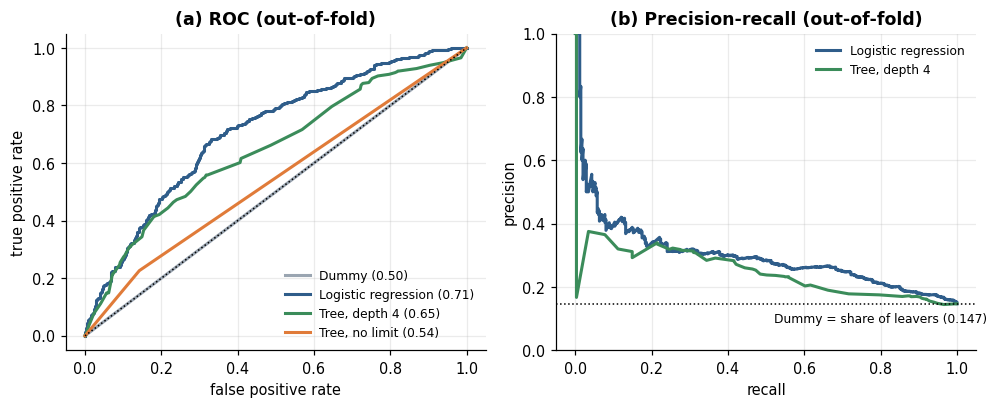

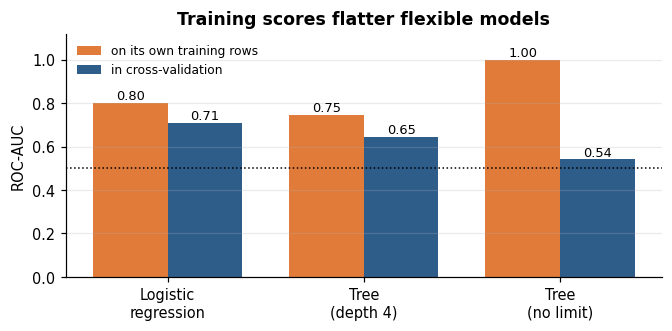

In [9]:
# Figures: ROC and PR curves from the out-of-fold probabilities, and training-vs-CV AUC
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.4, 3.8))
styles = {"Dummy (always stays)": (GREY, "Dummy"), "Logistic Regression (balanced)": (BLUE, "Logistic regression"),
          "Decision Tree (depth 4, balanced)": (GREEN, "Tree, depth 4"), "Decision Tree (no depth limit, balanced)": (ORANGE, "Tree, no limit")}
for name, (c, lab) in styles.items():
    fpr, tpr, _ = roc_curve(y, oof[name]); a1.plot(fpr, tpr, color=c, lw=2, label=f"{lab} ({roc_auc_score(y, oof[name]):.2f})")
    if name in ("Logistic Regression (balanced)", "Decision Tree (depth 4, balanced)"):      # Dummy / unlimited tree have too few distinct scores: their PR "curve" is just a misleading straight line
        pr, rc, _ = precision_recall_curve(y, oof[name]); a2.plot(rc, pr, color=c, lw=2, label=lab)
a1.plot([0, 1], [0, 1], ":", color="k", lw=1); a1.set_xlabel("false positive rate"); a1.set_ylabel("true positive rate"); a1.set_title("(a) ROC (out-of-fold)"); a1.legend(frameon=False, fontsize=8, loc="lower right")
a2.axhline(y.mean(), ls=":", color="k", lw=1); a2.text(0.52, y.mean() - .06, f"Dummy = share of leavers ({y.mean():.3f})", fontsize=8); a2.legend(frameon=False, fontsize=8, loc="upper right")
a2.set_xlabel("recall"); a2.set_ylabel("precision"); a2.set_title("(b) Precision-recall (out-of-fold)"); a2.set_ylim(0, 1)
plt.tight_layout(); plt.savefig(FIGURES / "fig5_roc_pr.png"); plt.show()

fig, ax = plt.subplots(figsize=(6.2, 3.1)); o = overfit.set_index("model"); x = np.arange(len(o)); w = .38
b1 = ax.bar(x - w/2, o.iloc[:, 0], w, color=ORANGE, label="on its own training rows"); b2 = ax.bar(x + w/2, o.iloc[:, 1], w, color=BLUE, label="in cross-validation")
ax.bar_label(b1, fmt="%.2f", fontsize=8.5); ax.bar_label(b2, fmt="%.2f", fontsize=8.5); ax.axhline(.5, ls=":", color="k", lw=1)
ax.set_xticks(x); ax.set_xticklabels(["Logistic\nregression", "Tree\n(depth 4)", "Tree\n(no limit)"]); ax.set_ylim(0, 1.12); ax.set_ylabel("ROC-AUC")
ax.set_title("Training scores flatter flexible models"); ax.legend(frameon=False, fontsize=8, loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(FIGURES / "fig6_train_vs_cv.png"); plt.show()

## 7. Is the gap believable?
Our logistic regression and the benchmark differ by a tiny amount. Is that difference bigger than the noise? Four checks, all with the **same folds**.

In [10]:
lrname = "Logistic Regression (balanced)"; plr = oof[lrname]
# (a) how much does the score move with the data and the split?
lo, hi = bootstrap_auc_interval(y, plr)
seed_aucs = [roc_auc_score(y, out_of_fold_proba(model_pipeline(clone(models[lrname])), X, y, make_folds(y, random_state=sd))) for sd in range(10)]
seed_tree = [roc_auc_score(y, out_of_fold_proba(model_pipeline(clone(models["Decision Tree (depth 4, balanced)"])), X, y, make_folds(y, random_state=sd))) for sd in range(10)]
R["noise"] = {"fold_sd": float(summary[lrname]["roc_auc_sd"]), "bootstrap_95ci": [lo, hi], "split_seed_mean": float(np.mean(seed_aucs)),
              "split_seed_sd": float(np.std(seed_aucs, ddof=1)), "split_seed_min": float(min(seed_aucs)), "split_seed_max": float(max(seed_aucs)),
              "tree4_split_seed_sd": float(np.std(seed_tree, ddof=1)), "pr_auc_fold_sd": float(summary[lrname]["pr_auc_sd"])}
print(f"(a) logistic regression ROC-AUC: fold-to-fold sd {R['noise']['fold_sd']:.3f} | bootstrap 95% interval {lo:.3f} to {hi:.3f} | "
      f"10 different fold splits: mean {R['noise']['split_seed_mean']:.3f}, sd {R['noise']['split_seed_sd']:.3f}, range {min(seed_aucs):.3f} to {max(seed_aucs):.3f}")
print(f"    PR-AUC fold-to-fold sd {R['noise']['pr_auc_fold_sd']:.3f} (ours {summary[lrname]['pr_auc_mean']:.3f} vs benchmark 0.332)")

# (b) control: shuffle the labels - a leak-free pipeline must drop to chance
ys = pd.Series(np.random.default_rng(0).permutation(y.values), index=y.index)
auc_shuffled = roc_auc_score(ys, out_of_fold_proba(model_pipeline(clone(models[lrname])), X, ys, folds))
# (c) control: preprocess ONCE on all rows, then cross-validate only the classifier (the 'naive' way)
from sklearn.model_selection import cross_val_predict
Xp = build_pipeline().fit_transform(X)
auc_naive = roc_auc_score(y, cross_val_predict(clone(models[lrname]), Xp, y, cv=folds, method="predict_proba")[:, 1])
print(f"(b) shuffled labels -> ROC-AUC {auc_shuffled:.3f} (chance = 0.5)")
print(f"(c) preprocessing fitted on ALL rows before CV -> {auc_naive:.4f} vs proper {roc_auc_score(y, plr):.4f}")
R["controls"] = {"shuffled_labels_auc": float(auc_shuffled), "naive_preprocessing_auc": float(auc_naive), "proper_auc": float(roc_auc_score(y, plr))}

(a) logistic regression ROC-AUC: fold-to-fold sd 0.018 | bootstrap 95% interval 0.679 to 0.737 | 10 different fold splits: mean 0.711, sd 0.005, range 0.703 to 0.716
    PR-AUC fold-to-fold sd 0.023 (ours 0.309 vs benchmark 0.332)


(b) shuffled labels -> ROC-AUC 0.487 (chance = 0.5)
(c) preprocessing fitted on ALL rows before CV -> 0.7103 vs proper 0.7103


In [11]:
# (d) feature-set variants (open items from Task 2): the IDENTICAL `folds` list, same model
variants = []
for label, kw in [("main feature set", {}), ("without the monthly attendance/payroll features", dict(use_monthly=False)),
                  ("with the UNCONFIRMED dept_attrition_rate_prior_12m", dict(include_unconfirmed=True))]:
    Xv, yv, _ = load_model_table(**kw)
    assert Xv.index.equals(X.index) and yv.equals(y)          # same rows in the same order, so the same folds apply
    pv = out_of_fold_proba(model_pipeline(clone(models[lrname]), **kw), Xv, yv, folds)
    variants.append({"logistic regression, " + "feature set": label, "input columns": Xv.shape[1], "ROC-AUC (pooled)": round(roc_auc_score(yv, pv), 4)})
variants = pd.DataFrame(variants); display(variants); R["variants"] = variants.to_dict("records")
assert (variants["ROC-AUC (pooled)"] - variants["ROC-AUC (pooled)"].iloc[0]).abs().max() < 0.002      # the markdown below says "less than 0.002"

# (e) per row source: the model was trained on the mix; how does it do on each part?
per_source = []
for s_name in sorted(source.unique()):
    m = (source == s_name).values
    lo_s, hi_s = bootstrap_auc_interval(y[m], plr[m])
    per_source.append({"rows": s_name, "n": int(m.sum()), "leavers": int(y[m].sum()), "ROC-AUC": round(roc_auc_score(y[m], plr[m]), 3), "bootstrap 95% interval": f"{lo_s:.2f} to {hi_s:.2f}"})
per_source = pd.DataFrame(per_source); display(per_source); R["per_source"] = per_source.to_dict("records")
pd.concat([variants.assign(check="feature set"), per_source.assign(check="row source")]).to_csv(TABLES / "day3_controls.csv", index=False)

,"logistic regression, feature set",input columns,ROC-AUC (pooled)
0,main feature set,33,0.7103
1,without the monthly attendance/payroll features,30,0.7105
2,with the UNCONFIRMED dept_attrition_rate_prior...,34,0.7095


,rows,n,leavers,ROC-AUC,bootstrap 95% interval
0,historical_extension,2000,299,0.714,0.68 to 0.74
1,master_employee_snapshot,379,50,0.688,0.61 to 0.76


**What the checks say.** The benchmark's 0.713 sits well inside the range our own score moves through just from re-splitting the data or resampling rows, so there is nothing here to explain. The shuffled-label control lands at chance, so the pipeline is not leaking labels into the scores, and fitting preprocessing outside the folds would not have changed the result *in this case* (we still do it properly). Removing the monthly features or adding the unconfirmed department rate moves the score by less than 0.002: neither helps measurably, which also means open item O2 does not change this conclusion. The two row sources behave differently (master-snapshot rows have only 50 leavers, hence a wide interval); Task 4 should keep reporting them separately.

## 8. Leakage alarm
A score above 0.9 sends us back to find leakage. The check below runs on every honest cross-validated score; the benchmark's leaky row shows what it catches.

In [12]:
honest = {k: v["roc_auc_mean"] for k, v in summary.items()}
check_suspicious_scores(honest)                       # raises SuspiciouslyGoodScoreError if any score > 0.9
print("All honest cross-validated ROC-AUC values are below", SUSPICIOUS_AUC, "->", {k: round(float(v), 3) for k, v in honest.items()})
try:
    check_suspicious_scores({"LEAKY Logistic Regression (benchmark sheet, adds exit information)": 1.0})
except SuspiciouslyGoodScoreError as e:
    print("\nThe alarm on the benchmark's leaky row:\n ", e)

All honest cross-validated ROC-AUC values are below 0.9 -> {'Dummy (always stays)': 0.5, 'Logistic Regression (balanced)': 0.712, 'Decision Tree (no depth limit, balanced)': 0.542, 'Decision Tree (depth 4, balanced)': 0.654}

The alarm on the benchmark's leaky row:
  Cross-validated ROC-AUC above 0.9: {'LEAKY Logistic Regression (benchmark sheet, adds exit information)': 1.0}. Scores this high on attrition almost always mean leakage (an exit column, the target, or future data in the features). Check the feature list first.


## 9. The 5-sentence note
Every claim below is checked by an assertion before it is printed, so the note cannot silently become wrong if the data or code changes.

In [13]:
lr, tr4, dm = summary[lrname], summary["Decision Tree (depth 4, balanced)"], summary["Dummy (always stays)"]
bm = bench.set_index("model")
b_lr, b_tr, b_pr = bm.loc["Logistic Regression (class_weight=balanced)"], bm.loc["Decision Tree (depth 4, balanced)"], None
N = R["noise"]
# claims
assert abs(lr["roc_auc_mean"] - b_lr.roc_auc_mean) < 0.03                        # near the benchmark
assert abs(tr4["roc_auc_mean"] - b_tr.roc_auc_mean) < 0.03
assert abs(lr["roc_auc_mean"] - b_lr.roc_auc_mean) < N["fold_sd"]                # gap smaller than fold noise
assert N["bootstrap_95ci"][0] <= b_lr.roc_auc_mean <= N["bootstrap_95ci"][1]     # benchmark inside our interval
assert abs(lr["pr_auc_mean"] - b_lr.pr_auc_mean) < 2 * N["pr_auc_fold_sd"]        # PR-AUC gap within noise
assert dm["roc_auc_mean"] == 0.5 and dm["recall_mean"] == 0
assert R["controls"]["shuffled_labels_auc"] < 0.55 and max(honest.values()) < SUSPICIOUS_AUC
note = [
 f"Our logistic regression reaches a ROC-AUC of {lr['roc_auc_mean']:.3f} (sd {lr['roc_auc_sd']:.3f} across the five folds) against the benchmark's {b_lr.roc_auc_mean:.3f}, so it is level with the benchmark, and the depth-4 tree ({tr4['roc_auc_mean']:.3f} vs {b_tr.roc_auc_mean:.3f}) and the Dummy model ({dm['roc_auc_mean']:.3f} ROC-AUC, {dm['accuracy_mean']:.3f} accuracy) match it too.",
 f"The one number below the benchmark is the logistic regression's PR-AUC ({lr['pr_auc_mean']:.3f} vs {b_lr.pr_auc_mean:.3f}), but that gap is smaller than twice the fold-to-fold sd of {N['pr_auc_fold_sd']:.3f} and we also used {R['rows']:,} rows after removing duplicates and negative-tenure rows, so exact equality was never expected.",
 f"The gaps are believable because they are tiny compared with the noise: changing the fold split moves our ROC-AUC by about {N['split_seed_sd']:.3f}, and a bootstrap 95% interval ({N['bootstrap_95ci'][0]:.3f} to {N['bootstrap_95ci'][1]:.3f}) contains the benchmark.",
 f"Nothing looks like leakage: every honest score is far below 0.9, a control run with shuffled labels scores {R['controls']['shuffled_labels_auc']:.2f} (chance), and fitting the preprocessing outside the folds changed nothing measurable.",
 f"The Dummy result shows why accuracy misleads (it is {dm['accuracy_mean']:.0%} accurate and catches nobody), and the logistic regression shows the problem is genuinely hard: it ranks a leaver above a stayer about {lr['roc_auc_pooled']:.0%} of the time, but at a 0.5 cut-off it catches {lr['recall_mean']:.0%} of leavers with only {lr['precision_mean']:.0%} precision, which Task 4 will judge properly.",
]
R["note"] = note
display(Markdown("\n\n".join(f"{i}. {s}" for i, s in enumerate(note, 1))))

1. Our logistic regression reaches a ROC-AUC of 0.712 (sd 0.018 across the five folds) against the benchmark's 0.713, so it is level with the benchmark, and the depth-4 tree (0.654 vs 0.650) and the Dummy model (0.500 ROC-AUC, 0.853 accuracy) match it too.

2. The one number below the benchmark is the logistic regression's PR-AUC (0.309 vs 0.332), but that gap is smaller than twice the fold-to-fold sd of 0.023 and we also used 2,379 rows after removing duplicates and negative-tenure rows, so exact equality was never expected.

3. The gaps are believable because they are tiny compared with the noise: changing the fold split moves our ROC-AUC by about 0.005, and a bootstrap 95% interval (0.679 to 0.737) contains the benchmark.

4. Nothing looks like leakage: every honest score is far below 0.9, a control run with shuffled labels scores 0.49 (chance), and fitting the preprocessing outside the folds changed nothing measurable.

5. The Dummy result shows why accuracy misleads (it is 85% accurate and catches nobody), and the logistic regression shows the problem is genuinely hard: it ranks a leaver above a stayer about 71% of the time, but at a 0.5 cut-off it catches 63% of leavers with only 26% precision, which Task 4 will judge properly.

In [14]:
R["random_state"], R["n_splits"] = RANDOM_STATE, N_SPLITS
(TABLES / "day3_findings.json").write_text(json.dumps(R, indent=2, default=str, allow_nan=True), encoding="utf-8")
print("saved reports/tables/day3_findings.json, day3_baseline_comparison.csv, day3_controls.csv and figures fig5, fig6")

saved reports/tables/day3_findings.json, day3_baseline_comparison.csv, day3_controls.csv and figures fig5, fig6
